# Training walkthrough: conformer generation on a curved (torsion) path

This notebook shows, one cell at a time, how TorsionFlow is trained and how it generates molecules.

It is a **toy version**, so it runs anywhere in a few minutes, even on a CPU:
- **Data:** a few QM9-sized molecules. Their "real" 3D shapes come from RDKit plus a force field. The project itself uses GEOM-QM9's CREST conformers.
- **Model:** a small graph network. The project itself uses Torsional Diffusion's E(3)-equivariant network.

Everything else is the real procedure: the curved path, the training target, the loss functions, the sampler, and the benchmark's scoring.

| Part | What it shows |
|---|---|
| A | The data: molecules and their real shapes |
| B | Which bonds can twist |
| C | Freezing bond lengths/angles, twisting bonds, and matching real shapes |
| D | **The curved path**, and why it keeps bonds intact |
| E | The model |
| F | One training step, by hand |
| G | Three loss functions |
| H | The training loop |
| I | Generating molecules, and how quality depends on the number of steps |
| J | **Research questions 1–2:** fake vs real multiple answers, and whether removing the fake ones helps |

Running everything takes about 8 minutes on a CPU (three models are trained: one in part H, two in part J).

In [1]:
import math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from rdkit.Geometry import Point3D

RDLogger.DisableLog("rdApp.*")            # silence RDKit deprecation chatter
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
# The toy model is tiny, so one CPU thread is the fastest option here, and it makes every run
# exactly repeatable (with several threads, numbers get added in a different order each run).
# The real model in step 4 uses the GPU.
torch.set_num_threads(1)
device = torch.device("cpu")
print("device:", device, "| threads:", torch.get_num_threads())

def wrap(x):
    "Wrap angles into [-pi, pi): the short way round the circle."
    return torch.remainder(x + math.pi, 2 * math.pi) - math.pi

device: cpu | threads: 1


## A. The data

A molecule can take many 3D shapes (**conformers**), mostly by twisting around its single bonds. The model's job: given a molecule's graph, produce realistic conformers.

Ground truth here: for each molecule, RDKit makes 30 random shapes (ETKDG), the MMFF force field relaxes each one, and near-duplicates are dropped. What's left is a small set of distinct low-energy shapes. That's the same kind of thing GEOM provides; GEOM just uses a more accurate method (CREST).

The molecules come in two groups. The first four are floppy chains. The last four contain a **symmetric group that moves heavy atoms** (tert-butyl, CF3, a phenyl ring); part J needs those.

In [2]:
SMILES = {                      # QM9-sized: 5-9 heavy atoms
    # floppy chains
    "pentane":             "CCCCC",
    "hexane":              "CCCCCC",
    "1-pentanol":          "CCCCCO",
    "1,2-dimethoxyethane": "COCCOC",
    # a symmetric group that moves heavy atoms, plus a floppy chain (for part J)
    "trifluorobutanol":    "OCCCC(F)(F)F",   # CF3: looks the same every 120 deg
    "trifluoropentane":    "CCCCC(F)(F)F",   # CF3
    "t-butyl propyl ether":"CCCOC(C)(C)C",   # tert-butyl: every 120 deg
    "propylbenzene":       "CCCc1ccccc1",    # phenyl ring: every 180 deg
}

# Not 0: in current RDKit, randomSeed=0 makes every embedded shape identical.
EMBED_SEED = 42

def make_ensemble(smi, n_embed=30, dedupe_rmsd=0.25):
    mol = Chem.AddHs(Chem.MolFromSmiles(smi))
    cids = list(AllChem.EmbedMultipleConfs(mol, numConfs=n_embed, randomSeed=EMBED_SEED))
    AllChem.MMFFOptimizeMoleculeConfs(mol, maxIters=2000)
    heavy = Chem.RemoveHs(mol)               # compare shapes on heavy atoms only
    keep = []
    for cid in cids:                         # keep a shape only if it differs from all kept ones
        if all(AllChem.GetBestRMS(heavy, heavy, prbId=cid, refId=k) > dedupe_rmsd for k in keep):
            keep.append(cid)
    return mol, [torch.tensor(mol.GetConformer(c).GetPositions(), dtype=torch.float32) for c in keep]

molecules = []
for name, smi in SMILES.items():
    mol, confs = make_ensemble(smi)
    molecules.append({"name": name, "smiles": smi, "mol": mol, "data": confs})
    print(f"{name:20s} {smi:11s} atoms incl. H: {mol.GetNumAtoms():2d}   distinct conformers: {len(confs)}")

pentane              CCCCC       atoms incl. H: 17   distinct conformers: 6
hexane               CCCCCC      atoms incl. H: 20   distinct conformers: 9


1-pentanol           CCCCCO      atoms incl. H: 18   distinct conformers: 15


1,2-dimethoxyethane  COCCOC      atoms incl. H: 16   distinct conformers: 12
trifluorobutanol     OCCCC(F)(F)F atoms incl. H: 15   distinct conformers: 8
trifluoropentane     CCCCC(F)(F)F atoms incl. H: 17   distinct conformers: 7


t-butyl propyl ether CCCOC(C)(C)C atoms incl. H: 24   distinct conformers: 4
propylbenzene        CCCc1ccccc1 atoms incl. H: 21   distinct conformers: 3


## B. Which bonds can twist

Same rule as Torsional Diffusion: a bond is **rotatable** if removing it splits the molecule into two pieces, and the smaller piece has more than one atom. Twisting the bond swings the smaller piece around the bond axis.

- Ring bonds are excluded: removing one doesn't split anything.
- Bonds to a single hydrogen are excluded: there's nothing to swing.
- Methyl groups (CH3) **are** included. Spinning a methyl by 120° gives the identical molecule, so its angle only matters modulo 120°. Hydrogens don't count in the evaluation score, but the model still has to predict them.

For each rotatable bond we record: `u` (the atom that stays), `v` (the atom on the swinging side), `mask` (which atoms swing), and two reference atoms `a`, `b` used to measure the angle a-u-v-b.

In [3]:
def rotatable_bonds(mol):
    n = mol.GetNumAtoms()
    nbrs = [[x.GetIdx() for x in mol.GetAtomWithIdx(i).GetNeighbors()] for i in range(n)]
    out = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        side, stack = {j}, [j]                 # atoms reachable from j without crossing j -> i
        while stack:
            x = stack.pop()
            for y in nbrs[x]:
                if (x == j and y == i) or y in side:
                    continue
                side.add(y); stack.append(y)
        if i in side:                          # i reachable another way: the bond is in a ring
            continue
        u, v = (i, j) if len(side) <= n - len(side) else (j, i)   # v = atom on the smaller side
        swing = side if v == j else set(range(n)) - side
        if len(swing) < 2:                     # e.g. a lone H: nothing to swing
            continue
        mask = torch.zeros(n, dtype=torch.bool); mask[list(swing)] = True
        a = min(x for x in nbrs[u] if x != v)
        b = min(x for x in nbrs[v] if x != u)
        out.append(dict(u=u, v=v, a=a, b=b, mask=mask))
    return out

for m in molecules:
    m["bonds"] = rotatable_bonds(m["mol"])
    sym = lambda k: m["mol"].GetAtomWithIdx(k).GetSymbol()
    desc = [f"{sym(d['u'])}-{sym(d['v'])} (swings {int(d['mask'].sum())} atoms)" for d in m["bonds"]]
    print(f"{m['name']:20s} {len(m['bonds'])} rotatable: " + ", ".join(desc))

pentane              4 rotatable: C-C (swings 4 atoms), C-C (swings 7 atoms), C-C (swings 7 atoms), C-C (swings 4 atoms)
hexane               5 rotatable: C-C (swings 4 atoms), C-C (swings 7 atoms), C-C (swings 10 atoms), C-C (swings 7 atoms), C-C (swings 4 atoms)
1-pentanol           5 rotatable: C-C (swings 4 atoms), C-C (swings 7 atoms), C-C (swings 8 atoms), C-C (swings 5 atoms), C-O (swings 2 atoms)
1,2-dimethoxyethane  5 rotatable: O-C (swings 4 atoms), C-O (swings 5 atoms), C-C (swings 8 atoms), C-O (swings 5 atoms), O-C (swings 4 atoms)
trifluorobutanol     4 rotatable: C-O (swings 2 atoms), C-C (swings 5 atoms), C-C (swings 7 atoms), C-C (swings 4 atoms)
trifluoropentane     4 rotatable: C-C (swings 4 atoms), C-C (swings 7 atoms), C-C (swings 7 atoms), C-C (swings 4 atoms)
t-butyl propyl ether 7 rotatable: C-C (swings 4 atoms), C-C (swings 7 atoms), O-C (swings 10 atoms), C-O (swings 11 atoms), C-C (swings 4 atoms), C-C (swings 4 atoms), C-C (swings 4 atoms)
propylbenzene     

## C. Frozen local structure, twisting bonds, and conformer matching

Torsion models freeze bond lengths and bond angles, and only change the twist angles (**torsions**). The frozen geometry, called the **local structure**, comes from one fresh RDKit shape.

Two tools, both plain differentiable PyTorch:
- `torsions` measures every rotatable bond's angle a-u-v-b.
- `apply_torsions` twists bonds: it rotates the swinging side around the bond axis using Rodrigues' rotation formula. This is the same operation as Torsional Diffusion's `modify_conformer`.

In [4]:
def dihedral(pos, a, u, v, b):
    "Torsion angle a-u-v-b in radians. pos is [B, N, 3]; returns [B]."
    b0, b1, b2 = pos[:, a] - pos[:, u], pos[:, v] - pos[:, u], pos[:, b] - pos[:, v]
    b1 = b1 / b1.norm(dim=-1, keepdim=True)
    p = b0 - (b0 * b1).sum(-1, keepdim=True) * b1
    q = b2 - (b2 * b1).sum(-1, keepdim=True) * b1
    return torch.atan2((torch.cross(b1, p, dim=-1) * q).sum(-1), (p * q).sum(-1))

def torsions(pos, bonds):
    "All rotatable-bond torsion angles: [B, K]."
    return torch.stack([dihedral(pos, d["a"], d["u"], d["v"], d["b"]) for d in bonds], dim=-1)

def apply_torsions(pos, bonds, delta):
    "Rotate the swinging side of bond k by delta[:, k] radians. pos [B, N, 3], delta [B, K]."
    for k, d in enumerate(bonds):
        pv = pos[:, d["v"]].unsqueeze(1)                          # pivot point
        axis = pos[:, d["u"]] - pos[:, d["v"]]
        axis = axis / axis.norm(dim=-1, keepdim=True)             # [B, 3]
        th = delta[:, k].view(-1, 1, 1)
        S = torch.zeros(pos.shape[0], 3, 3, device=pos.device, dtype=pos.dtype)
        S[:, 0, 1], S[:, 0, 2], S[:, 1, 2] = -axis[:, 2], axis[:, 1], -axis[:, 0]
        S = S - S.transpose(1, 2)                                 # skew matrix of the axis
        R = torch.eye(3, device=pos.device) + torch.sin(th) * S + (1 - torch.cos(th)) * (S @ S)
        moved = (pos - pv) @ R.transpose(1, 2) + pv
        pos = torch.where(d["mask"].to(pos.device).view(1, -1, 1), moved, pos)
    return pos

def local_structure(mol, seed=123):
    "One fresh RDKit shape: its bond lengths and angles get frozen."
    m2 = Chem.Mol(mol); m2.RemoveAllConformers()
    AllChem.EmbedMolecule(m2, randomSeed=seed)
    return torch.tensor(m2.GetConformer().GetPositions(), dtype=torch.float32)

for m in molecules:
    m["local"] = local_structure(m["mol"])

**Check the tools before trusting them.** Twist one bond by 0.5 rad. Only that bond's torsion should change, by exactly ±0.5, and no bond length should change.

The ± is a sign convention: depending on which way the rotation axis points and how the angle is defined, rotating by +θ changes the measured angle by +θ or by −θ. Rather than trust a convention, we **measure** it and store it as `SIGN`. From then on, `twist` always means "change the torsion angles by this much".

In [5]:
def bond_lengths(pos, mol):
    idx = torch.tensor([[b.GetBeginAtomIdx(), b.GetEndAtomIdx()] for b in mol.GetBonds()])
    return (pos[:, idx[:, 0]] - pos[:, idx[:, 1]]).norm(dim=-1)

m = molecules[0]                                              # pentane
k = max(range(len(m["bonds"])), key=lambda i: int(m["bonds"][i]["mask"].sum()))  # biggest swing
x = m["local"].unsqueeze(0)
delta = torch.zeros(1, len(m["bonds"])); delta[0, k] = 0.5
y = apply_torsions(x, m["bonds"], delta)

change = wrap(torsions(y, m["bonds"]) - torsions(x, m["bonds"]))[0]
SIGN = round(change[k].item() / 0.5)
print("torsion change per bond (rad):", [round(c, 5) for c in change.tolist()])
print("measured sign convention SIGN =", SIGN)
print("largest bond-length change (Å):", (bond_lengths(y, m["mol"]) - bond_lengths(x, m["mol"])).abs().max().item())

def twist(pos, bonds, dphi):
    "Change the torsion angles by dphi (radians, in the units `torsions` measures)."
    return apply_torsions(pos, bonds, SIGN * dphi)

torsion change per bond (rad): [0.0, -0.5, 0.0, 0.0]
measured sign convention SIGN = -1
largest bond-length change (Å): 2.384185791015625e-07


**Conformer matching.** Re-express each real shape as *local structure + torsions*: measure the real shape's torsions, then twist the local structure to the same angles.

The result has the real torsions, but RDKit's bond lengths and angles. So it can't match the real shape perfectly. That leftover error is the **floor**: the best any torsion-only model can do. On GEOM-QM9 the Torsional Diffusion paper puts it at about 0.17 Å.

The matched shapes are what the model is trained to produce.

In [6]:
def to_rdkit(mol, pos):
    "Heavy-atom RDKit molecule with coordinates pos ([N, 3], all atoms)."
    m2 = Chem.Mol(mol); m2.RemoveAllConformers()
    conf = Chem.Conformer(mol.GetNumAtoms())
    for i, (x, y, z) in enumerate(pos.tolist()):
        conf.SetAtomPosition(i, Point3D(x, y, z))
    m2.AddConformer(conf, assignId=True)
    return Chem.RemoveHs(m2)

def rmsd(mol, P, Q):
    "Best-alignment RMSD on heavy atoms, symmetry-aware (same function evaluate_confs.py uses)."
    return AllChem.GetBestRMS(to_rdkit(mol, P), to_rdkit(mol, Q))

for m in molecules:
    B, loc = m["bonds"], m["local"].unsqueeze(0)
    data = torch.stack(m["data"])
    m["matched"] = torch.cat([twist(loc, B, wrap(torsions(x.unsqueeze(0), B) - torsions(loc, B)))
                              for x in data])
    err = wrap(torsions(m["matched"], B) - torsions(data, B)).abs().max().item()
    m["floor"] = np.mean([rmsd(m["mol"], a, b) for a, b in zip(m["matched"], data)])
    print(f"{m['name']:20s} torsions reproduced to {err:.0e} rad,  RMSD matched vs real: {m['floor']:.3f} Å")

print(f"\naverage floor: {np.mean([m['floor'] for m in molecules]):.3f} Å")
for m in molecules:                                           # model inputs live on the device
    m["local"], m["matched"] = m["local"].to(device), m["matched"].to(device)

pentane              torsions reproduced to 5e-07 rad,  RMSD matched vs real: 0.101 Å
hexane               torsions reproduced to 7e-07 rad,  RMSD matched vs real: 0.087 Å
1-pentanol           torsions reproduced to 7e-07 rad,  RMSD matched vs real: 0.081 Å
1,2-dimethoxyethane  torsions reproduced to 5e-07 rad,  RMSD matched vs real: 0.054 Å


trifluorobutanol     torsions reproduced to 7e-07 rad,  RMSD matched vs real: 0.129 Å
trifluoropentane     torsions reproduced to 7e-07 rad,  RMSD matched vs real: 0.072 Å
t-butyl propyl ether torsions reproduced to 5e-07 rad,  RMSD matched vs real: 0.187 Å
propylbenzene        torsions reproduced to 2e-07 rad,  RMSD matched vs real: 0.055 Å

average floor: 0.096 Å


## D. The curved path

Training pairs a **random** starting shape with a **real** one, and teaches the model the velocity along the path between them.

In torsion coordinates: start = real torsions + a random offset δ (uniform around the circle). The path shrinks the offset to zero:

$$x_t = \text{twist}\big(x_1,\ (1-t)\,\delta\big), \qquad t: 0 \to 1$$

Each torsion turns at a constant speed, so the velocity is constant: **−δ**. That's the training target.

Wrap-around makes this the short way round: δ is kept in [−π, π), so no torsion turns more than half a circle. Here's the 170° → −170° example:

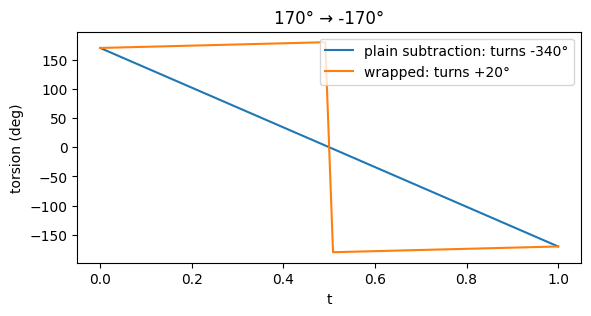

In [7]:
start, end = math.radians(170), math.radians(-170)
t = torch.linspace(0, 1, 60)
naive = start + t * (end - start)                        # plain subtraction: -340 degrees
short = start + t * wrap(torch.tensor(end - start))      # wrapped: +20 degrees

plt.figure(figsize=(6.5, 3))
plt.plot(t, torch.rad2deg(wrap(naive)), label="plain subtraction: turns -340°")
plt.plot(t, torch.rad2deg(wrap(short)), label="wrapped: turns +20°")
plt.xlabel("t"); plt.ylabel("torsion (deg)"); plt.title("170° → -170°"); plt.legend(); plt.show()

**Why curved?** Compare with a straight line in x,y,z space between the same two shapes. To be fair to the straight line, the start is first rotated to line up with the end (Kabsch alignment), so it doesn't waste motion.

Twisting keeps every bond length exact the whole way. The straight line squashes and stretches bonds in the middle, so the network would have to learn to repair broken molecules. This is the core of your original idea.

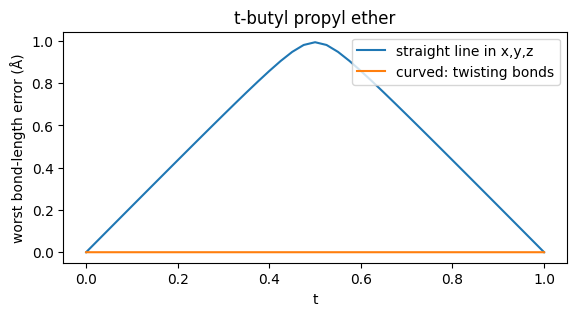

worst bond-length error along the path:  straight 0.994 Å,  curved 8e-07 Å


In [8]:
def kabsch_align(P, Q):
    "Rotate and translate P ([N, 3]) onto Q."
    Pc, Qc = P - P.mean(0), Q - Q.mean(0)
    U, S, Vt = torch.linalg.svd(Pc.T @ Qc)
    d = torch.sign(torch.det(Vt.T @ U.T)).item()
    R = Vt.T @ torch.diag(torch.tensor([1.0, 1.0, d])) @ U.T
    return Pc @ R.T + Q.mean(0)

m = max(molecules, key=lambda m: len(m["bonds"]))        # the molecule with most rotatable bonds
B, x1 = m["bonds"], m["matched"][:1].cpu()
torch.manual_seed(1)
delta = wrap(torch.rand(1, len(B)) * 2 * math.pi)        # random offset = random start
x0 = twist(x1, B, delta)
ref = bond_lengths(x1, m["mol"])

ts = torch.linspace(0, 1, 41)
curved = [(bond_lengths(twist(x1, B, (1 - t) * delta), m["mol"]) - ref).abs().max().item() for t in ts]
x0a = kabsch_align(x0[0], x1[0]).unsqueeze(0)
straight = [(bond_lengths((1 - t) * x0a + t * x1, m["mol"]) - ref).abs().max().item() for t in ts]

plt.figure(figsize=(6.5, 3))
plt.plot(ts, straight, label="straight line in x,y,z")
plt.plot(ts, curved, label="curved: twisting bonds")
plt.xlabel("t"); plt.ylabel("worst bond-length error (Å)"); plt.title(m["name"]); plt.legend(); plt.show()
print(f"worst bond-length error along the path:  straight {max(straight):.3f} Å,  curved {max(curved):.0e} Å")

## E. The model

**Input:** the molecule's graph, the **current torsion angles** (as sin and cos), and the time t.
**Output:** one velocity per rotatable bond.

Why torsions as input? With bond lengths and angles frozen, the torsions describe the shape completely. They don't change when the whole molecule is rotated or moved, so the model doesn't have to learn that. And they flip sign in a mirror image, so left- and right-handed shapes stay distinct.

The network: atom and bond features → 3 rounds of message passing along bonds → for each rotatable bond, a small MLP reads the two end atoms plus that bond's torsion and outputs a velocity. The two ends are read in a fixed order (stays-side, swings-side), because the direction of a twist depends on which side swings.

**Toy limitation:** messages only travel along bonds, so this model can't directly "see" two distant atoms bumping into each other in space. Torsional Diffusion's network also connects all atoms within 5 Å and sees 3D directions. That's what step 4 uses.

In [9]:
ELEMENTS = ["H", "C", "N", "O", "F"]
BOND_TYPES = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE, Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]

def graph_features(mol, bonds):
    atoms = [[a.GetSymbol() == e for e in ELEMENTS] + [a.GetDegree() == d for d in (1, 2, 3, 4)]
             + [a.GetIsAromatic(), a.IsInRing()] for a in mol.GetAtoms()]
    rot = {frozenset((d["u"], d["v"])): k for k, d in enumerate(bonds)}
    src, dst, feats, tors = [], [], [], []
    for bd in mol.GetBonds():
        i, j = bd.GetBeginAtomIdx(), bd.GetEndAtomIdx()
        k = rot.get(frozenset((i, j)), -1)                  # which torsion this bond is, or -1
        for s, t_ in ((i, j), (j, i)):                      # messages flow both ways
            src.append(s); dst.append(t_)
            feats.append([bd.GetBondType() == bt for bt in BOND_TYPES] + [k >= 0]); tors.append(k)
    g = dict(atoms=torch.tensor(atoms, dtype=torch.float32), src=torch.tensor(src), dst=torch.tensor(dst),
             edges=torch.tensor(feats, dtype=torch.float32), torsion_of_edge=torch.tensor(tors),
             u=torch.tensor([d["u"] for d in bonds]), v=torch.tensor([d["v"] for d in bonds]))
    return {key: val.to(device) for key, val in g.items()}

for m in molecules:
    m["graph"] = graph_features(m["mol"], m["bonds"])
g = molecules[0]["graph"]
print(f"pentane graph: {g['atoms'].shape[0]} atoms x {g['atoms'].shape[1]} features, "
      f"{len(g['src'])} directed edges x {g['edges'].shape[1]} features")

pentane graph: 17 atoms x 11 features, 32 directed edges x 5 features


In [10]:
def time_embedding(t, dim=16):
    "Sinusoidal embedding of t in [0, 1]: the usual way to tell a network the time."
    freqs = torch.exp(torch.linspace(0, math.log(1000), dim // 2, device=t.device))
    ang = t.view(-1, 1) * freqs
    return torch.cat([ang.sin(), ang.cos()], dim=-1)

class TorsionVelocityNet(nn.Module):
    def __init__(self, hidden=64, layers=3, n_atom=11, n_edge=5):
        super().__init__()
        self.atom_in = nn.Linear(n_atom, hidden)
        self.time_in = nn.Sequential(nn.Linear(16, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.msg = nn.ModuleList(nn.Sequential(nn.Linear(2 * hidden + n_edge + 2, hidden), nn.SiLU(),
                                               nn.Linear(hidden, hidden)) for _ in range(layers))
        self.norm = nn.ModuleList(nn.LayerNorm(hidden) for _ in range(layers))
        self.out = nn.Sequential(nn.Linear(2 * hidden + 2, hidden), nn.SiLU(), nn.Linear(hidden, 1))

    def forward(self, g, phi, t):
        "g: graph of ONE molecule; phi: current torsions [B, K]; t: [B]. Returns velocities [B, K]."
        Bsz = phi.shape[0]
        trig = torch.stack([phi.sin(), phi.cos()], -1)                     # [B, K, 2]
        k = g["torsion_of_edge"]                                           # put each torsion on its bond
        etrig = torch.zeros(Bsz, len(k), 2, device=phi.device)
        etrig[:, k >= 0] = trig[:, k[k >= 0]]
        e = torch.cat([g["edges"].expand(Bsz, -1, -1), etrig], -1)
        h = self.atom_in(g["atoms"]).expand(Bsz, -1, -1) + self.time_in(time_embedding(t)).unsqueeze(1)
        deg = torch.zeros(h.shape[1], device=h.device).index_add_(
            0, g["dst"], torch.ones(len(g["dst"]), device=h.device)).clamp(min=1)
        for msg, norm in zip(self.msg, self.norm):
            m_ = msg(torch.cat([h[:, g["src"]], h[:, g["dst"]], e], -1))   # one message per edge
            agg = torch.zeros_like(h).index_add_(1, g["dst"], m_) / deg.view(1, -1, 1)   # average incoming
            h = norm(h + agg)
        return self.out(torch.cat([h[:, g["u"]], h[:, g["v"]], trig], -1)).squeeze(-1)

model = TorsionVelocityNet().to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
m = molecules[4]
x = m["matched"][torch.randint(len(m["matched"]), (4,))]     # 4 shapes, with replacement
phi = torsions(x, m["bonds"])
v = model(m["graph"], phi, torch.rand(4, device=device))
print(f"{m['name']}: torsions {tuple(phi.shape)} -> velocities {tuple(v.shape)}")

parameters: 53,441
trifluorobutanol: torsions (4, 4) -> velocities (4, 4)


## F. One training step, by hand

This is the whole training recipe for one batch:

1. Pick a molecule, and B of its matched real shapes x₁.
2. Draw a random offset δ, uniform on [−π, π), for every rotatable bond. That defines the random start.
3. Draw a time t, uniform on [0, 1].
4. Build x_t by twisting x₁ by (1−t)·δ.
5. Target velocity = −δ. Ask the model, compare, backpropagate.

In [11]:
def sym_numbers(m, sym):
    "Part J. False: every twist is 360°. True: all symmetric groups. 'heavy': only groups that move heavy atoms."
    if not sym:
        return None
    return m["n"] if sym is True else m["n_heavy"]

def make_batch(m, B, n=None):
    # n: symmetry number of each twist (part J). None means 1: every twist is a full 360° circle.
    # With n, the model works with n*angle, so a group that repeats every 360°/n looks like one point.
    n = torch.ones(len(m["bonds"]), device=device) if n is None else n
    x1 = m["matched"][torch.randint(len(m["matched"]), (B,))]          # 1. real shapes
    delta = wrap(torch.rand(B, len(m["bonds"]), device=device) * 2 * math.pi)   # 2. random offset
    t = torch.rand(B, device=device)                                    # 3. time
    xt = twist(x1, m["bonds"], (1 - t).view(-1, 1) * delta / n)         # 4. point on the path
    return dict(x1=x1, xt=xt, phi_t=n * torsions(xt, m["bonds"]), t=t, target=-delta, n=n)   # 5. target

m = molecules[0]
b = make_batch(m, B=8)
for key, val in b.items():
    print(f"  {key:7s} shape {tuple(val.shape)}")

phi1 = torsions(b["x1"], m["bonds"])
off = wrap(b["phi_t"] - phi1 + (1 - b["t"]).view(-1, 1) * b["target"]).abs().max().item()
print(f"\nx_t really sits at phi_1 + (1-t)*delta:  {off < 1e-4}  (max error {off:.0e} rad)")

pred = model(m["graph"], b["phi_t"], b["t"])
loss = F.mse_loss(pred, b["target"])
loss.backward()
gnorm = torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters())).item()
print(f"loss = {loss.item():.3f}   (always predicting 0 would score about pi^2/3 = {math.pi ** 2 / 3:.3f})")
print(f"gradient norm = {gnorm:.3f}")
model.zero_grad()

  x1      shape (8, 17, 3)
  xt      shape (8, 17, 3)
  phi_t   shape (8, 4)
  t       shape (8,)
  target  shape (8, 4)
  n       shape (4,)

x_t really sits at phi_1 + (1-t)*delta:  True  (max error 5e-07 rad)
loss = 4.051   (always predicting 0 would score about pi^2/3 = 3.290)
gradient norm = 1.364


## G. Three loss functions

Three ways to score a prediction. Step 5 of the project compares them properly; here they're just defined and checked.

1. **Velocity MSE.** Compare predicted and true velocity. The standard flow-matching loss and the default here.
2. **Endpoint angle loss.** Turn the velocity into a predicted destination, φ̂₁ = φ_t + (1−t)·v̂, and score the angle error with 1 − cos(error), which handles wrap-around correctly. The error equals (1−t)·(v̂ − v), so it fades out near t = 1 and puts its weight on early times, which is where 1-step generation lives.
3. **3D loss.** Actually twist x_t to the predicted destination and compare atom-to-atom distances with the real shape (heavy atoms). A twist that swings a big chunk of the molecule costs more than spinning a methyl group; the angle losses treat them the same. It uses distances instead of RMSD, so no alignment step is needed.

In [12]:
def loss_velocity_mse(pred, b, m):
    return F.mse_loss(pred, b["target"])

def loss_endpoint_cos(pred, b, m):
    err = (1 - b["t"]).view(-1, 1) * (pred - b["target"])     # predicted minus true destination
    return (1 - torch.cos(err)).mean()

def loss_3d_distances(pred, b, m):
    x1_hat = twist(b["xt"], m["bonds"], (1 - b["t"]).view(-1, 1) * pred / b["n"])   # go to predicted end
    D = lambda x: torch.cdist(x[:, m["heavy"]], x[:, m["heavy"]])
    return F.mse_loss(D(x1_hat), D(b["x1"]))

LOSSES = {"velocity_mse": loss_velocity_mse, "endpoint_cos": loss_endpoint_cos, "3d_distances": loss_3d_distances}

for m in molecules:
    m["heavy"] = torch.tensor([a.GetIdx() for a in m["mol"].GetAtoms() if a.GetAtomicNum() > 1], device=device)

m = molecules[4]
b = make_batch(m, 16)
pred = model(m["graph"], b["phi_t"], b["t"])
print("untrained model:   ", {name: round(fn(pred, b, m).item(), 4) for name, fn in LOSSES.items()})
print("perfect prediction:", {name: round(fn(b["target"], b, m).item(), 6) for name, fn in LOSSES.items()})

untrained model:    {'velocity_mse': 2.6754, 'endpoint_cos': 0.3806, '3d_distances': 0.1666}
perfect prediction: {'velocity_mse': 0.0, 'endpoint_cos': 0.0, '3d_distances': 0.0}


## H. The training loop

The loop repeats part F: each step picks a random molecule, builds a batch, and takes an Adam step. Change `LOSS` to train with a different loss from part G.

The loop is wrapped in a function, `train`, because part J trains more models with the identical loop. Its one option, `sym`, switches the symmetry fix on (part J).

**The loss won't reach zero, and it shouldn't.** From the same x_t, several real shapes are possible destinations, and the model can only learn the *average* velocity toward them. That leftover is the multi-modality that makes 1-step generation hard. (Methyl groups add to it: their three equivalent positions are three equally valid targets.)

Training takes about 2–3 minutes on a CPU.

In [13]:
LOSS = "velocity_mse"            # or "endpoint_cos", "3d_distances"
STEPS, BATCH, LR = 8000, 64, 1e-3

def train(sym=False, seed=SEED):
    torch.manual_seed(seed); random.seed(seed)
    model = TorsionVelocityNet().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS)
    history, start = [], time.time()
    for step in range(1, STEPS + 1):
        m = random.choice(molecules)
        b = make_batch(m, BATCH, sym_numbers(m, sym))
        loss = LOSSES[LOSS](model(m["graph"], b["phi_t"], b["t"]), b, m)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        history.append(loss.item())
        if step % 1000 == 0:
            print(f"step {step:5d}   loss {np.mean(history[-1000:]):.4f}   ({time.time() - start:.0f} s)")
    return model, history

model, history = train()

step  1000   loss 3.2200   (13 s)


step  2000   loss 2.4051   (26 s)


step  3000   loss 2.1104   (39 s)


step  4000   loss 1.9862   (51 s)


step  5000   loss 1.8978   (64 s)


step  6000   loss 1.8517   (77 s)


step  7000   loss 1.8244   (89 s)


step  8000   loss 1.8037   (102 s)


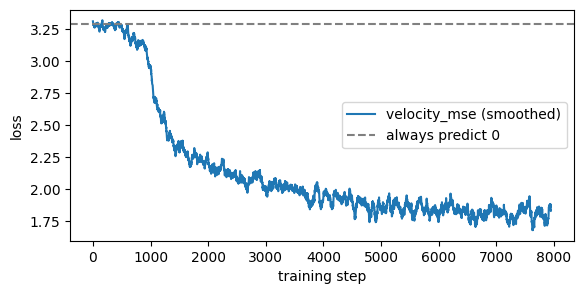

In [14]:
plt.figure(figsize=(6.5, 3))
plt.plot(np.convolve(history, np.ones(50) / 50, mode="valid"), label=f"{LOSS} (smoothed)")
if LOSS == "velocity_mse":
    plt.axhline(math.pi ** 2 / 3, ls="--", c="gray", label="always predict 0")
plt.xlabel("training step"); plt.ylabel("loss"); plt.legend(); plt.show()

## I. Generating molecules, and how many steps it takes

Generation runs the path forward with the learned velocity:

1. Start from the local structure with **random** torsions (t = 0).
2. Repeat S times: measure the torsions, ask the model for velocities, twist by velocity × 1/S.

S = 1 is a single jump. Fewer steps is faster; **project gap 2 is about making S = 1 or 2 as good as S = 20.**

In [15]:
@torch.no_grad()
def generate(model, m, count, steps, sym=False):
    n = sym_numbers(m, sym)                                              # symmetry numbers (part J)
    n = torch.ones(len(m["bonds"]), device=device) if n is None else n
    x = twist(m["local"].expand(count, -1, -1), m["bonds"],
              wrap(torch.rand(count, len(m["bonds"]), device=device) * 2 * math.pi))   # random start
    for i in range(steps):
        t = torch.full((count,), i / steps, device=device)
        v = model(m["graph"], n * torsions(x, m["bonds"]), t)
        x = twist(x, m["bonds"], v / (n * steps))
    return x

m = molecules[2]
x = generate(model, m, count=4, steps=20)
print(f"{m['name']}: generated {tuple(x.shape)}")
print("torsions (deg):", torch.rad2deg(torsions(x, m["bonds"])).round().int().tolist())

1-pentanol: generated (4, 18, 3)
torsions (deg): [[55, 63, 172, 180, 177], [-56, -59, -62, -56, -60], [-65, 63, 178, 176, -178], [179, -175, -70, 69, -179]]


**Scoring**, the same way as the real benchmark. For a molecule with K real shapes, generate 2K.
- **AMR-R** (lower is better): for each real shape, the RMSD to the closest generated one, averaged.
- **COV-R** (higher is better): % of real shapes that have a generated one within 0.5 Å, QM9's threshold.
- **AMR-P** (lower is better): the other direction. For each *generated* shape, the RMSD to the closest real one, averaged. It measures how good each sample is, not how much variety there is.

With only 3–15 real shapes per molecule, one miss moves COV-R by several points, so it's noisy here. The AMR numbers are steadier.

Rows: random torsions (no model), the model with 1, 2, 5 and 20 steps, and the floor (the matched shapes themselves, the best a torsion-only model can do with this local structure).

In [16]:
def score(m, gen, thresh=0.5):
    real = [to_rdkit(m["mol"], x) for x in m["data"]]
    fake = [to_rdkit(m["mol"], x) for x in gen.cpu()]
    R = np.array([[AllChem.GetBestRMS(f, r) for f in fake] for r in real])    # [real, generated]
    return R.min(1).mean(), (R.min(1) < thresh).mean() * 100, R.min(0).mean()

torch.manual_seed(SEED)
rows = {"random torsions (no model)": lambda m, n: generate(model, m, n, steps=0)}
for s in (1, 2, 5, 20):
    rows[f"model, {s} step" + ("s" if s > 1 else "")] = (lambda s: lambda m, n: generate(model, m, n, s))(s)
rows["floor (matched shapes)"] = lambda m, n: m["matched"]

results = {}
print(f"{'':28s}{'AMR-R (Å)':>11s}{'COV-R (%)':>11s}{'AMR-P (Å)':>11s}")
for label, gen_fn in rows.items():
    amr_r, cov_r, amr_p = zip(*[score(m, gen_fn(m, 2 * len(m["data"]))) for m in molecules])
    results[label] = (np.mean(amr_r), np.mean(cov_r), np.mean(amr_p))
    print(f"{label:28s}{np.mean(amr_r):11.3f}{np.mean(cov_r):11.1f}{np.mean(amr_p):11.3f}")

                              AMR-R (Å)  COV-R (%)  AMR-P (Å)
random torsions (no model)        0.348       83.2      0.447


model, 1 step                     0.263       95.2      0.325
model, 2 steps                    0.282       90.2      0.318


model, 5 steps                    0.202       88.3      0.236


model, 20 steps                   0.219       84.5      0.206
floor (matched shapes)            0.096      100.0      0.096


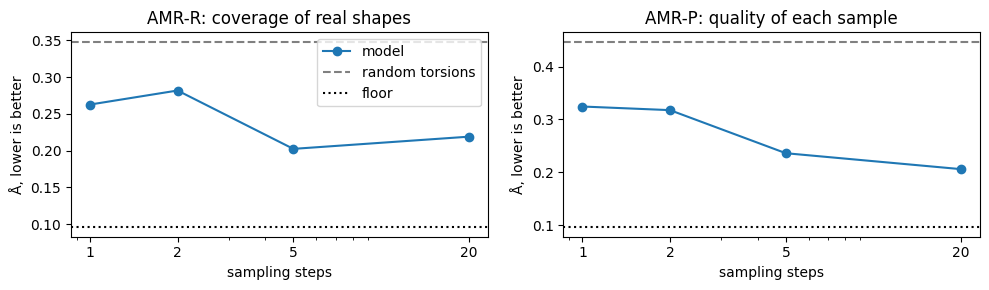

In [17]:
steps_list = [1, 2, 5, 20]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col, name in zip(axes, (0, 2), ("AMR-R: coverage of real shapes", "AMR-P: quality of each sample")):
    ax.plot(steps_list, [results[f"model, {s} step" + ("s" if s > 1 else "")][col] for s in steps_list], "o-", label="model")
    ax.axhline(results["random torsions (no model)"][col], ls="--", c="gray", label="random torsions")
    ax.axhline(results["floor (matched shapes)"][col], ls=":", c="k", label="floor")
    ax.set_xscale("log"); ax.set_xticks(steps_list, steps_list)
    ax.set_xlabel("sampling steps"); ax.set_ylabel("Å, lower is better"); ax.set_title(name)
axes[0].legend(); plt.tight_layout(); plt.show()

## What this shows, and what changes in the real version

**The full training procedure, end to end:** data → matching → curved path → target velocity → loss → loop → sampler → benchmark score.

**The table is gap 2 in miniature:** quality as a function of sampling steps. In my test run, 1 step was clearly worse than 5 or 20. Sample quality (AMR-P) kept improving up to 20 steps; coverage (AMR-R) is noisier and levelled off around 5. Few-step methods (Reflow, consistency, distillation; project step 6) try to make 1–2 steps as good as 20.

**Why is 1 step worse?** The model learned the *average* velocity (part H). A single jump along an average from a random start lands *between* the real shapes instead of on one of them. More steps let it re-aim along the way. This is the mode-averaging problem from the graph probe, now visible on molecules.

**Don't read the numbers as results.** Toy data, a toy model, a few small molecules, and only one training run.

**Next, part J** asks whether some of that averaging is avoidable.

**What step 4 changes:**
- Data: GEOM-QM9's CREST conformers, with Torsional Diffusion's local structures and conformer matching (step 2 sets this up).
- Model: Torsional Diffusion's E(3)-equivariant network, which sees 3D neighbourhoods, not just bonds.
- Batches mix many molecules instead of one molecule per step.
- Scoring: `evaluate_confs.py` on the 1000 test molecules.
- The `LOSS` switch here becomes step 5's loss comparison.

## J. Fake vs real multiple answers (research questions 1 and 2)

Some groups look identical after a partial turn: CH3, CF3 and tert-butyl every 120°, a phenyl ring every 180°. Everything above (and Torsional Diffusion's code) treats their twist as a full 360° circle. So a CH3 group's three identical positions count as three *different* correct answers. These are **fake** multiple answers. Pentane's anti vs gauche shapes are **real** ones.

The fix for fake ones is exact. For a group that repeats every 360°/n, the model works with n × angle. Then the n identical positions are the same point on a circle, and the model can't treat them as different. Nothing else changes: same network, same training loop, same seed, same sampler. One variable.

**Predictions, written before running:**
1. A large share of the ambiguity at the start of generation is fake, mostly from CH3 groups, which only move hydrogens.
2. The symmetry-aware model's training loss settles lower.
3. Generation improves for the molecules whose symmetric group moves **heavy atoms** (last four), especially at 1–2 steps. For the chains, little change: their symmetric groups only move hydrogens, which the score ignores.

If prediction 3 fails, the fix doesn't help the score, whatever happens to the loss.

**Step 1: find each twist's symmetry number.** A group on the end of a bond repeats every 360°/k if its other neighbours are all chemically identical: 3 identical neighbours on a tetrahedral atom (k = 3), or 2 on a flat atom (k = 2). Both ends of the bond count: a 3-fold group on one end and a 2-fold group on the other repeats every 60°, so n = lcm(3, 2) = 6.

"Chemically identical" uses RDKit's canonical ranking, which gives equal rank to atoms that are equivalent by the molecule's symmetry.

In [18]:
def symmetry_order(mol, x, partner, ranks):
    "How often the group on atom x repeats when turning about bond x-partner, and whether it moves heavy atoms."
    atom = mol.GetAtomWithIdx(x)
    others = [nb.GetIdx() for nb in atom.GetNeighbors() if nb.GetIdx() != partner]
    need = {Chem.HybridizationType.SP3: 3, Chem.HybridizationType.SP2: 2}.get(atom.GetHybridization())
    if need is None or len(others) != need or len({ranks[i] for i in others}) > 1:
        return 1, False
    return need, mol.GetAtomWithIdx(others[0]).GetAtomicNum() > 1

for m in molecules:
    ranks = list(Chem.CanonicalRankAtoms(m["mol"], breakTies=False))
    orders, heavy = [], []
    for d in m["bonds"]:
        ku, hu = symmetry_order(m["mol"], d["u"], d["v"], ranks)
        kv, hv = symmetry_order(m["mol"], d["v"], d["u"], ranks)
        orders.append(math.lcm(ku, kv))
        heavy.append((ku > 1 and hu) or (kv > 1 and hv))
    m["n"] = torch.tensor(orders, dtype=torch.float32, device=device)
    m["n_heavy"] = torch.tensor([o if h else 1 for o, h in zip(orders, heavy)], dtype=torch.float32, device=device)
    m["sym_heavy"] = heavy
    m["group"] = "heavy symmetric group" if any(heavy) else "chain"
    sym = lambda k: m["mol"].GetAtomWithIdx(k).GetSymbol()
    desc = [f"{sym(d['u'])}-{sym(d['v'])} every {360 // o}°{' (heavy atoms)' if h else ' (H only)'}"
            for d, o, h in zip(m["bonds"], orders, heavy) if o > 1]
    print(f"{m['name']:20s} {m['group']:22s} symmetric twists: {', '.join(desc) or 'none'}")

pentane              chain                  symmetric twists: C-C every 120° (H only), C-C every 120° (H only)
hexane               chain                  symmetric twists: C-C every 120° (H only), C-C every 120° (H only)
1-pentanol           chain                  symmetric twists: C-C every 120° (H only)
1,2-dimethoxyethane  chain                  symmetric twists: O-C every 120° (H only), O-C every 120° (H only)
trifluorobutanol     heavy symmetric group  symmetric twists: C-C every 120° (heavy atoms)
trifluoropentane     heavy symmetric group  symmetric twists: C-C every 120° (H only), C-C every 120° (heavy atoms)
t-butyl propyl ether heavy symmetric group  symmetric twists: C-C every 120° (H only), C-O every 120° (heavy atoms), C-C every 120° (H only), C-C every 120° (H only), C-C every 120° (H only)
propylbenzene        heavy symmetric group  symmetric twists: C-C every 120° (H only), C-C every 180° (heavy atoms)


**Question 1: how much of the ambiguity is fake?**

At the start of generation (t = 0) the shape is random, and has nothing to do with which real shape it will end up as. So for each twist, the best any model can do is predict the *average* move toward that twist's real angles. The leftover error is the **spread** of those moves.

That spread can be computed **exactly** from the data. No model and no training: just the real angles, and every possible starting angle on a fine grid. We compute it twice, once treating every twist as 360° and once with the symmetry fix. **The difference is the fake part.** Errors are in radians² of actual twisting, so the two are directly comparable.

In [19]:
def start_ambiguity(phi1, n, grid=720):
    "Exact leftover error at t=0 for one twist. phi1: its real angles [K]. Returns rad^2 of actual twist."
    psi0 = torch.linspace(-math.pi, math.pi, grid + 1)[:-1]              # every possible start
    moves = wrap(n * phi1.view(1, -1) - psi0.view(-1, 1))                # [grid, K] move to each real angle
    return (moves.var(dim=1, unbiased=False).mean() / n ** 2).item()     # spread, averaged over starts

totals = {"all": [0.0, 0.0], "heavy": [0.0, 0.0], "H only": [0.0, 0.0], "not symmetric": [0.0, 0.0]}
print(f"{'':20s}{'360° everywhere':>16s}{'symmetry-aware':>16s}{'fake share':>12s}")
for m in molecules:
    phi1 = torsions(m["matched"], m["bonds"]).cpu()
    full = [start_ambiguity(phi1[:, k], 1.0) for k in range(len(m["bonds"]))]
    quot = [start_ambiguity(phi1[:, k], float(m["n"][k])) for k in range(len(m["bonds"]))]
    for k in range(len(m["bonds"])):
        kind = "not symmetric" if m["n"][k] == 1 else ("heavy" if m["sym_heavy"][k] else "H only")
        for key in ("all", kind):
            totals[key][0] += full[k]; totals[key][1] += quot[k]
    share = f"{100 * (1 - sum(quot) / sum(full)):11.0f}%" if sum(full) > 0 else "-".rjust(12)
    print(f"{m['name']:20s}{sum(full):16.2f}{sum(quot):16.2f}{share}")

f, q = totals["all"]
print(f"\nall twists, all molecules: {f:.1f} -> {q:.1f} rad^2   fake share {100 * (1 - q / f):.0f}%")
for key in ("H only", "heavy", "not symmetric"):
    print(f"   of the fake part, from {key:14s}: {100 * (totals[key][0] - totals[key][1]) / (f - q):5.1f}%")

                     360° everywhere  symmetry-aware  fake share
pentane                        11.03            6.14         44%
hexane                         12.48            8.14         35%
1-pentanol                     14.01           11.58         17%
1,2-dimethoxyethane            13.62            8.59         37%
trifluorobutanol                9.44            7.15         24%
trifluoropentane               11.16            6.00         46%
t-butyl propyl ether           18.14            4.99         72%
propylbenzene                   5.74            3.34         42%

all twists, all molecules: 95.6 -> 55.9 rad^2   fake share 42%
   of the fake part, from H only        :  81.0%
   of the fake part, from heavy         :  19.0%
   of the fake part, from not symmetric :   0.0%


**Question 2: does removing the fake part help?**

Train a second model with `sym=True`. Same loop, same seed, same number of steps (another 2–3 minutes on a CPU).

Both models' training targets are spread evenly over [−π, π) in their own units, so "always predict 0" scores π²/3 for both, and the two loss curves are on the same scale.

In [20]:
model_sym, history_sym = train(sym=True)

step  1000   loss 2.3054   (13 s)


step  2000   loss 1.6287   (25 s)


step  3000   loss 1.4455   (38 s)


step  4000   loss 1.3561   (51 s)


step  5000   loss 1.2840   (63 s)


step  6000   loss 1.2621   (76 s)


step  7000   loss 1.2295   (88 s)


step  8000   loss 1.2085   (100 s)


**Follow-up: fix only the groups that move heavy atoms.** CH3 groups only move hydrogens, which the score ignores, so fixing them can't help the score directly. A third model applies the fix only to CF3, tert-butyl and phenyl groups and leaves CH3 at 360°. If the full fix has a hidden cost, this version should avoid it while keeping the gain.

In [21]:
model_heavy, history_heavy = train(sym="heavy")

step  1000   loss 3.0705   (12 s)


step  2000   loss 2.4205   (25 s)


step  3000   loss 2.1480   (38 s)


step  4000   loss 2.0067   (51 s)


step  5000   loss 1.9205   (64 s)


step  6000   loss 1.8701   (76 s)


step  7000   loss 1.8325   (89 s)


step  8000   loss 1.8207   (102 s)


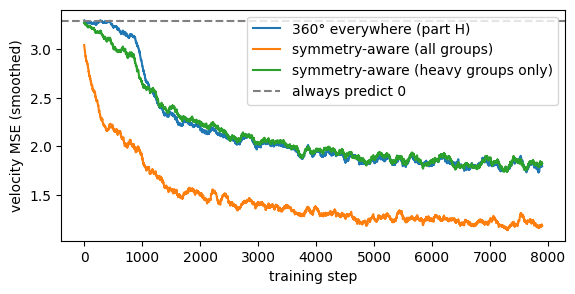

final loss (mean of last 1000 steps):  360° everywhere 1.804,  symmetry-aware 1.209,  heavy only 1.821


In [22]:
smooth = lambda h: np.convolve(h, np.ones(100) / 100, mode="valid")
plt.figure(figsize=(6.5, 3))
plt.plot(smooth(history), label="360° everywhere (part H)")
plt.plot(smooth(history_sym), label="symmetry-aware (all groups)")
plt.plot(smooth(history_heavy), label="symmetry-aware (heavy groups only)")
plt.axhline(math.pi ** 2 / 3, ls="--", c="gray", label="always predict 0")
plt.xlabel("training step"); plt.ylabel("velocity MSE (smoothed)"); plt.legend(); plt.show()
print(f"final loss (mean of last 1000 steps):  360° everywhere {np.mean(history[-1000:]):.3f},  "
      f"symmetry-aware {np.mean(history_sym[-1000:]):.3f},  heavy only {np.mean(history_heavy[-1000:]):.3f}")

**Generation, scored per group.** For a fair comparison, all three models start from **exactly the same random shapes** for every molecule and step count (the random seed is reset before each model). So any difference comes from the models, not from luck in the starting points.

In [23]:
ARMS = {"360°": (model, False), "sym": (model_sym, True), "heavy": (model_heavy, "heavy")}
paired = {}                                     # (steps, arm) -> per-molecule [AMR-R, COV-R, AMR-P]
for s in (1, 2, 5, 20):
    for name, (mdl, sym_flag) in ARMS.items():
        torch.manual_seed(SEED + s)             # same random starts for every model
        paired[(s, name)] = np.array([score(m, generate(mdl, m, 2 * len(m["data"]), s, sym=sym_flag))
                                      for m in molecules])

for group in ("chain", "heavy symmetric group"):
    idx = [i for i, m in enumerate(molecules) if m["group"] == group]
    print(f"\n{group} ({len(idx)} molecules)        AMR-R (Å)                     AMR-P (Å)")
    print(f"{'steps':>7s}" + "".join(f"{a:>10s}" for a in ARMS) + "  " + "".join(f"{a:>10s}" for a in ARMS))
    for s in (1, 2, 5, 20):
        r = [paired[(s, a)][idx].mean(0) for a in ARMS]
        print(f"{s:7d}" + "".join(f"{x[0]:10.3f}" for x in r) + "  " + "".join(f"{x[2]:10.3f}" for x in r))


chain (4 molecules)        AMR-R (Å)                     AMR-P (Å)
  steps      360°       sym     heavy        360°       sym     heavy
      1     0.282     0.288     0.284       0.306     0.325     0.314
      2     0.273     0.277     0.291       0.318     0.318     0.315
      5     0.225     0.229     0.244       0.248     0.212     0.263
     20     0.147     0.152     0.173       0.197     0.186     0.197

heavy symmetric group (4 molecules)        AMR-R (Å)                     AMR-P (Å)
  steps      360°       sym     heavy        360°       sym     heavy
      1     0.317     0.275     0.283       0.385     0.342     0.359
      2     0.291     0.296     0.260       0.355     0.348     0.307
      5     0.204     0.194     0.216       0.219     0.162     0.198
     20     0.183     0.207     0.202       0.166     0.162     0.184


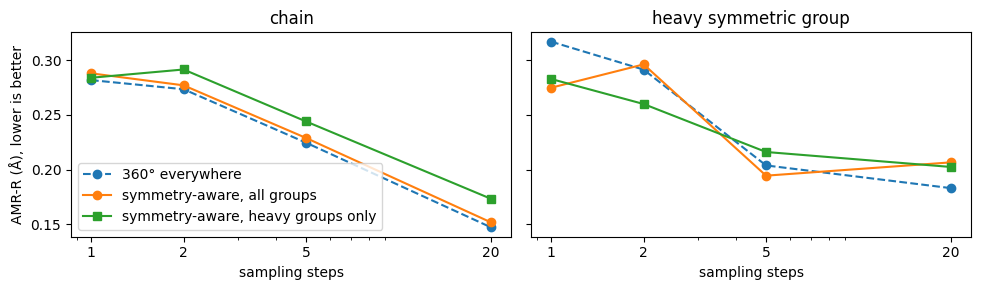

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
steps_list = [1, 2, 5, 20]
for ax, group in zip(axes, ("chain", "heavy symmetric group")):
    idx = [i for i, m in enumerate(molecules) if m["group"] == group]
    for name, style, label in (("360°", "o--", "360° everywhere"), ("sym", "o-", "symmetry-aware, all groups"),
                               ("heavy", "s-", "symmetry-aware, heavy groups only")):
        ax.plot(steps_list, [paired[(s, name)][idx, 0].mean() for s in steps_list], style, label=label)
    ax.set_xscale("log"); ax.set_xticks(steps_list, steps_list)
    ax.set_xlabel("sampling steps"); ax.set_title(group)
axes[0].set_ylabel("AMR-R (Å), lower is better"); axes[0].legend(); plt.tight_layout(); plt.show()

### What part J found

This notebook shows one training run (seed 0). One run can be luck, so I ran **the same code with 5 seeds** (0–4) outside the notebook. Because the notebook uses one CPU thread, each seed is exactly repeatable, so the differences below come from the models, not from arithmetic noise.

Change vs "360° everywhere", averaged over 5 seeds (negative = better), with how many seeds improved in brackets.

**Molecules with a heavy-atom symmetric group** (CF3, tert-butyl, phenyl). Baseline 1-step AMR-R: 0.294 Å.

| steps | AMR-R, fix all groups | AMR-R, fix heavy only | AMR-P, fix all groups | AMR-P, fix heavy only |
|---|---|---|---|---|
| 1 | −0.024 [4/5] | −0.025 [4/5] | −0.028 [4/5] | −0.027 [5/5] |
| 2 | −0.024 [4/5] | −0.034 [5/5] | −0.033 [5/5] | −0.041 [5/5] |
| 5 | −0.016 [5/5] | −0.009 [4/5] | −0.031 [5/5] | −0.006 [3/5] |
| 20 | −0.023 [3/5] | −0.016 [2/5] | −0.016 [4/5] | −0.011 [4/5] |

**Chains** (their symmetric groups are CH3, which only move hydrogens). Baseline 1-step AMR-R: 0.274 Å.

| steps | AMR-R, fix all groups | AMR-R, fix heavy only | AMR-P, fix all groups | AMR-P, fix heavy only |
|---|---|---|---|---|
| 1 | +0.025 [0/5] | +0.013 [0/5] | +0.017 [0/5] | +0.004 [1/5] |
| 2 | +0.012 [0/5] | +0.012 [1/5] | +0.008 [0/5] | +0.001 [2/5] |
| 5 | −0.001 [2/5] | +0.007 [1/5] | −0.013 [5/5] | +0.014 [0/5] |
| 20 | +0.008 [2/5] | +0.001 [2/5] | −0.002 [3/5] | +0.002 [1/5] |

Training loss (last 1000 steps): 1.80 (360°), 1.22 (fix all groups), 1.80 (fix heavy only), consistent across seeds.

**Against the predictions:**
1. ✅ **42% of the starting ambiguity is fake**; 81% of that comes from CH3 groups. Exact, not a training result.
2. ✅ for "fix all": the loss drops from 1.80 to 1.22. But that was nearly guaranteed: removing fake answers from the targets lowers the loss almost by definition. "Fix heavy only" leaves the loss unchanged, because heavy groups are only 19% of the fake part.
3. **Mostly.** ✅ Molecules with a heavy-atom symmetric group improve with both versions, most consistently at **1–2 steps** (about 0.025–0.035 Å, roughly 8–12%, in 4–5 of 5 seeds). ❌ Chains get **worse** at 1–2 steps when CH3 groups are fixed too: +0.025 Å at 1 step, in **every** seed. I predicted "little change"; this is a real effect, not noise.

**A clue about the chain cost.** "Fix heavy only" halves it (+0.013 Å at 1 step). Yet that version changes **nothing** about the chain molecules: their inputs and targets are identical to the 360° model's. So the remaining cost can only come indirectly: all molecules share one network, and changing how some molecules are trained changes what the network learns for the others.

**Verdict: the idea works where it should, but it isn't free.** Removing fake answers for groups that move heavy atoms makes 1–2 step generation better for those molecules. With one shared network, it costs a little on other molecules, and also fixing CH3 groups (which don't affect the score) doubles that cost. **Best version so far: fix heavy groups only.**

**How strong is this evidence?** The direction is consistent across 5 seeds, but 5 seeds can't prove much: even 5 out of 5 happens by pure chance about 6% of the time. Toy model, 8 molecules. Enough to justify the next step, not enough to publish.

**Next:**
1. **How much does this matter on real data?** Heavy-atom symmetric groups are uncommon in QM9 (at most 9 heavy atoms) but very common in drug-like molecules (phenyl rings, CF3). Question 1, measured on real GEOM conformers, answers this with no training.
2. **Understand the shared-network cost.** Does it shrink with a bigger network, or with per-molecule loss weighting?